# Preliminary Mlflow

**Purpose.** The original preliminary pipeline (MLflow, end-to-end fine-tuning of 7 transformers). Documents the result the thesis critiques.

**Thesis reference.** §5.1 Preliminary Work

**Inputs / outputs.** See the data-layout table in the repository README. Paths near the top of the notebook (e.g. `PROFILE_DIR`, `IMAGE_ROOT`, `LABELS`) are relative to the repository root and assume the folder layout described there.

---

In [161]:
pip install "mlflow==1.30.0"

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 17.0/17.0 MB 36.5 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 150.3/150.3 kB 2.6 MB/s eta 0:00:00ta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 148.1/148.1 kB 1.8 MB/s eta 0:00:00ta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 96.1/96.1 kB 2.3 MB/s eta 0:00:00ta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 79.5/79.5 kB 1.3 MB/s eta 0:00:00eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 40.8/40.8 kB 243.7 kB/s eta 0:00:00a 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 39.2 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 499.4/499.4 kB 8.4 MB/s eta 0:00:00:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.6/1.6 MB 19.8 MB/s eta 0:00:00:00:01
  Attempting uninstall: pytz
    Found existing installation: pytz 2023.3.post1
    Uninstalling pytz-2023.3.post1:
      Successfully uninstalled pytz-2023.3.post1
  Attempting uninstall: sqlalchemy
    F

In [72]:
print(mlflow.__version__)

1.30.0


In [2]:
import os
import pandas as pd
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt
import io
import time
import uuid
import re
import random
import mlflow

from torchvision import transforms
from torch.utils.data import Dataset, DataLoader, Subset
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torchvision.models import resnet18, ResNet18_Weights, vgg16_bn, VGG16_BN_Weights, efficientnet_b0, EfficientNet_B0_Weights

import mlflow
import mlflow.pytorch
from mlflow.models.signature import infer_signature
from mlflow import models

from PIL import Image
from scipy.signal import cwt, ricker

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score, roc_auc_score, f1_score

In [4]:
print(f"MLflow client version: {mlflow.__version__}")

MLflow client version: 1.30.0


In [3]:
NGROK_FORWARDING_URL = "https://228a-185-56-250-35.ngrok-free.app"  
MLFLOW_TRACKING_URI = NGROK_FORWARDING_URL

print(f"NGROK_FORWARDING_URL: {NGROK_FORWARDING_URL}")
print(f"MLFLOW_TRACKING_URI set to: {MLFLOW_TRACKING_URI}")

print(os.environ.get("MLFLOW_TRACKING_URI"))
print(os.environ.get("MLFLOW_ARTIFACT_ROOT")) 

try:
    mlflow.set_tracking_uri(MLFLOW_TRACKING_URI)
    print(f"Successfully set tracking URI. mlflow.get_tracking_uri() reports: {mlflow.get_tracking_uri()}")
except Exception as e:
    print(f"Error setting tracking URI: {e}")
    raise

NGROK_FORWARDING_URL: https://228a-185-56-250-35.ngrok-free.app
MLFLOW_TRACKING_URI set to: https://228a-185-56-250-35.ngrok-free.app
None
None
Successfully set tracking URI. mlflow.get_tracking_uri() reports: https://228a-185-56-250-35.ngrok-free.app


In [5]:
unique_suffix = str(uuid.uuid4())[:8]
EXPERIMENT_NAME = f"CKD_{unique_suffix}"

print(f"\nAttempting to create or set experiment: {EXPERIMENT_NAME}")

try:
    experiment = mlflow.get_experiment_by_name(EXPERIMENT_NAME)
    if experiment is None:
        print(f"Experiment '{EXPERIMENT_NAME}' not found. Creating it WITH EXPLICIT ARTIFACT LOCATION...")
  
        explicit_artifact_location_relative_to_server_root = EXPERIMENT_NAME
        experiment_id_str = mlflow.create_experiment(
            name=EXPERIMENT_NAME,
            artifact_location=f"mlflow-artifacts:/{explicit_artifact_location_relative_to_server_root}"
        )
        print(f"Successfully created new experiment '{EXPERIMENT_NAME}' with ID: {experiment_id_str} and forced artifact_location.")
        experiment = mlflow.get_experiment(experiment_id_str)
    else:
        experiment_id_str = experiment.experiment_id
        print(f"Using existing experiment '{EXPERIMENT_NAME}' with ID: {experiment_id_str}")

    print(f"  Experiment Name: {experiment.name}")
    print(f"  Experiment ID: {experiment.experiment_id}")
    print(f"  CRITICAL CHECK - Experiment Artifact Location: {experiment.artifact_location}") 

    mlflow.set_experiment(experiment_name=EXPERIMENT_NAME)
    print(f"Successfully set active experiment to '{EXPERIMENT_NAME}'")

except Exception as e:
    print(f"Error during experiment creation or setting for '{EXPERIMENT_NAME}': {e}")
    import traceback
    traceback.print_exc()
    raise

client_identifier = "aachen"

timestamp = int(time.time())
run_name = f"{client_identifier}_Run_{timestamp}"

print(f"\nStarting MLflow run: {run_name} for client: {client_identifier}")
try:
    with mlflow.start_run(run_name=run_name) as run:
        print(f"  Successfully started MLflow Run.")
        print(f"    Run ID: {run.info.run_id}")
        print(f"    Experiment ID (from run info): {run.info.experiment_id}")
        print(f"    CRITICAL CHECK - Artifact URI (for this run, from run info): {run.info.artifact_uri}")

        mlflow.log_param("client_type", client_identifier)
        dummy_artifact_filename = f"test_artifact_{client_identifier.lower()}.txt"
        local_artifact_file_path = os.path.join(os.getcwd(), dummy_artifact_filename)
        with open(local_artifact_file_path, "w") as f:
            f.write("Test content for artifact location.")
        print(f"  Created local artifact file: {local_artifact_file_path}")

        print(f"  Attempting to log artifact '{local_artifact_file_path}'")
        mlflow.log_artifact(local_artifact_file_path, artifact_path="client_specific_artifacts")
        print(f"  Artifact '{dummy_artifact_filename}' logged successfully to server.")
        os.remove(local_artifact_file_path)

        print(f"\n--- Test from {client_identifier} Successful ---")

except Exception as e:
    print(f"\n--- Test from {client_identifier} FAILED ---")
    print(f"An error occurred: {e}")
    import traceback
    traceback.print_exc()
    raise


Attempting to create or set experiment: CKD_969e9008
Experiment 'CKD_969e9008' not found. Creating it WITH EXPLICIT ARTIFACT LOCATION...
Successfully created new experiment 'CKD_969e9008' with ID: 145120164245519147 and forced artifact_location.
  Experiment Name: CKD_969e9008
  Experiment ID: 145120164245519147
  CRITICAL CHECK - Experiment Artifact Location: mlflow-artifacts:/CKD_969e9008
Successfully set active experiment to 'CKD_969e9008'

Starting MLflow run: aachen_Run_1750080835 for client: aachen
  Successfully started MLflow Run.
    Run ID: e370ba65165444ae8cc6220bc97d4129
    Experiment ID (from run info): 145120164245519147
    CRITICAL CHECK - Artifact URI (for this run, from run info): mlflow-artifacts:/CKD_969e9008/e370ba65165444ae8cc6220bc97d4129/artifacts
  Created local artifact file: /home/jovyan/work/aachen/hana/test_artifact_aachen.txt
  Attempting to log artifact '/home/jovyan/work/aachen/hana/test_artifact_aachen.txt'
  Artifact 'test_artifact_aachen.txt' logged

In [4]:
diab_wo_ckd = ["P0067", "P0187", "P0231", "P0486", "P0488", "P0508", "P0510", "P0511", "P0556", "P0603", "P0609",
               "P0744", "P0767", "P0778", "P0784", "P0800", "P0832", "P0834", "P0858", "P0863", "P0869", "P0876",
               "P0895", "P0934", "P0938", "P0950", "P0960", "P0961", "P0963", "P0964", "P0967", "P0969", "P0976",
               "P0981", "P1000", "P1004", "P1009", "P1010", "P1011", "P1015", "P1024", "P1030", "P1032", "P1033"]

diab_ckd1 = ["P0045", "P0098", "P0110", "P0210", "P0279", "P0309", "P0316", "P0332", "P0375", "P0470", "P0598", "P0605",
             "P0690", "P0753", "P0783", "P0819", "P0909", "P0922", "P0925", "P0948", "P0965", "P0966", "P0968", "P0974",
             "P1007", "P1008", "P1012", "P1018", "P1021", "P1025", "P1028", "P1029"]

diab_ckd2 = ["P0004", "P0010", "P0013", "P0069", "P0070", "P0079", "P0080", "P0083", "P0103", "P0143", "P0160", "P0161",
             "P0175", "P0181", "P0199", "P0203", "P0205", "P0213", "P0214", "P0223", "P0226", "P0238", "P0240", "P0246",
             "P0260", "P0261", "P0285", "P0318", "P0327", "P0330", "P0341", "P0358", "P0362", "P0364", "P0369", "P0383",
             "P0391", "P0399", "P0411", "P0419", "P0447", "P0459", "P0463", "P0466", "P0480", "P0483", "P0490", "P0495",
             "P0497", "P0499", "P0506", "P0518", "P0558", "P0600", "P0611", "P0614", "P0618", "P0620", "P0624", "P0628",
             "P0631", "P0654", "P0662", "P0672", "P0679", "P0689", "P0699", "P0708", "P0711", "P0715", "P0729", "P0759",
             "P0775", "P0787", "P0795", "P0804", "P0822", "P0826", "P0830", "P0848", "P0859", "P0873", "P0882", "P0883",
             "P0884", "P0903", "P0911", "P0919", "P0932", "P0946", "P0970", "P0972", "P0975", "P0977", "P0994", "P0998",
             "P1006", "P1013", "P1016", "P1017", "P1022", "P1026"]

diab_ckd3 = ["P0009", "P0012", "P0101", "P0115", "P0121", "P0137", "P0138", "P0172", "P0179", "P0182", "P0184", "P0194",
             "P0202", "P0221", "P0242", "P0265", "P0266", "P0269", "P0288", "P0310", "P0317", "P0326", "P0328", "P0334",
             "P0337", "P0342", "P0360", "P0376", "P0378", "P0385", "P0402", "P0404", "P0413", "P0414", "P0416", "P0425",
             "P0441", "P0452", "P0465", "P0476", "P0477", "P0485", "P0515", "P0523", "P0536", "P0545", "P0547", "P0550",
             "P0551", "P0568", "P0571", "P0572", "P0577", "P0602", "P0612", "P0621", "P0622", "P0634", "P0636", "P0645",
             "P0647", "P0660", "P0661", "P0663", "P0665", "P0667", "P0670", "P0680", "P0691", "P0692", "P0701", "P0702",
             "P0709", "P0748", "P0752", "P0821", "P0825", "P0843", "P0868", "P0880", "P0929", "P0973", "P1014", "P1027"]

diab_ckd4 = ["P0118", "P0222", "P0361", "P0445", "P0451", "P0656", "P0657", "P0760"]

diabetes_patients_non_ckd = ['P0067', 'P0187', 'P0231', 'P0486', 'P0488', 'P0508', 'P0510', 'P0511', 'P0556', 'P0603', 'P0609',
                     'P0744', 'P0767', 'P0778', 'P0784', 'P0800', 'P0832', 'P0834', 'P0858', 'P0863', 'P0869', 'P0876',
                     'P0895', 'P0934', 'P0938', 'P0950', 'P0960', 'P0961', 'P0963', 'P0964', 'P0967', 'P0969', 'P0976',
                     'P0981', 'P1000', 'P1004', 'P1009', 'P1010', 'P1011', 'P1015', 'P1024', 'P1030', 'P1032', 'P1033']

diabetes_patients_ckd = ['P0009', 'P0012', 'P0101', 'P0115', 'P0121', 'P0137', 'P0138', 'P0172', 'P0179', 'P0182',
                         'P0184', 'P0194', 'P0202', 'P0221', 'P0242', 'P0265', 'P0266', 'P0269', 'P0288', 'P0310',
                         'P0317', 'P0326', 'P0328', 'P0334', 'P0337', 'P0342', 'P0360', 'P0376', 'P0378', 'P0385',
                         'P0402', 'P0404', 'P0413', 'P0414', 'P0416', 'P0425', 'P0441', 'P0452', 'P0465', 'P0476',
                         'P0477', 'P0485', 'P0515', 'P0523', 'P0536', 'P0545', 'P0547', 'P0550', 'P0551', 'P0568',
                         'P0571', 'P0572', 'P0577', 'P0602', 'P0612', 'P0621', 'P0622', 'P0634', 'P0636', 'P0645',
                         'P0647', 'P0660', 'P0661', 'P0663', 'P0665', 'P0667', 'P0670', 'P0680', 'P0691', 'P0692',
                         'P0701', 'P0702', 'P0709', 'P0748', 'P0752', 'P0821', 'P0825', 'P0843', 'P0868', 'P0880',
                         'P0929', 'P0973', 'P1014', 'P1027', 'P0118', 'P0222', 'P0361', 'P0445', 'P0451', 'P0656',
                         'P0657', 'P0760']

non_diabetes_patients_non_ckd = ["P0038", "P0047", "P0048", "P0062", "P0126", "P0140", "P0157", "P0159", "P0166", "P0248",
                         "P0252", "P0254", "P0267", "P0290", "P0304", "P0340", "P0392", "P0396", "P0421", "P0450",
                         "P0479", "P0484", "P0509", "P0512", "P0513", "P0526", "P0546", "P0626", "P0648", "P0735",
                         "P0745", "P0758", "P0769", "P0771", "P0782", "P0786", "P0794", "P0806", "P0809", "P0813",
                         "P0823", "P0831", "P0835", "P0853", "P0861", "P0864", "P0872", "P0877", "P0886", "P0887",
                         "P0890", "P0896", "P0901", "P0904", "P0905", "P0907", "P0924", "P0926", "P0940", "P0945",
                         "P0947", "P1001"]

non_diabetes_patients_ckd = ["P0005", "P0009", "P0012", "P0018", "P0022", "P0052", "P0055", "P0068", "P0085", "P0092",
                             "P0099", "P0101", "P0115", "P0120", "P0121", "P0124", "P0125", "P0133", "P0135", "P0137",
                             "P0138", "P0153", "P0155", "P0167", "P0168", "P0172", "P0179", "P0180", "P0182", "P0184",
                             "P0185", "P0194", "P0196", "P0201", "P0202", "P0211", "P0221", "P0225", "P0236", "P0237",
                             "P0239", "P0242", "P0247", "P0265", "P0266", "P0269", "P0276", "P0288", "P0300", "P0310",
                             "P0312", "P0317", "P0319", "P0325", "P0326", "P0328", "P0334", "P0337", "P0342", "P0345",
                             "P0354", "P0357", "P0360", "P0371", "P0376", "P0377", "P0378", "P0385", "P0397", "P0398",
                             "P0402", "P0404", "P0407", "P0412", "P0413", "P0414", "P0415", "P0416", "P0418", "P0425",
                             "P0429", "P0437", "P0440", "P0441", "P0446", "P0452", "P0465", "P0475", "P0476", "P0477",
                             "P0478", "P0485", "P0487", "P0491", "P0496", "P0514", "P0515", "P0523", "P0536", "P0537",
                             "P0539", "P0540", "P0541", "P0542", "P0545", "P0547", "P0550", "P0551", "P0553", "P0561",
                             "P0568", "P0571", "P0572", "P0574", "P0577", "P0586", "P0589", "P0595", "P0596", "P0602",
                             "P0612", "P0616", "P0621", "P0622", "P0634", "P0635", "P0636", "P0642", "P0645", "P0647",
                             "P0651", "P0653", "P0659", "P0660", "P0661", "P0663", "P0665", "P0667", "P0668", "P0670",
                             "P0671", "P0675", "P0680", "P0691", "P0692", "P0693", "P0698", "P0701", "P0702", "P0709",
                             "P0731", "P0732", "P0747", "P0748", "P0752", "P0774", "P0776", "P0779", "P0781", "P0789",
                             "P0790", "P0807", "P0821", "P0825", "P0833", "P0836", "P0843", "P0849", "P0868", "P0880",
                             "P0898", "P0906", "P0910", "P0929", "P0973", "P1014", "P1023", "P1027", "P0118", "P0222",
                             "P0333", "P0361", "P0381", "P0445", "P0451", "P0503", "P0516", "P0527", "P0656", "P0657",
                             "P0681", "P0751", "P0760", "P0597"]

In [29]:
def load_and_downsample(filepath, sample_size=100_000):
    df = pd.read_csv(filepath, sep='\t', names=["time", "mz", "intensity"], dtype=str, low_memory=False)
    
    for col in ["time", "mz", "intensity"]:
        df[col] = pd.to_numeric(df[col], errors="coerce")
    
    df = df.dropna(subset=["time", "mz", "intensity"])
    
    if len(df) > sample_size:
        df = df.sample(n=sample_size, random_state=42)
    
    return df

In [30]:
def convert_to_histogram_image(df, bins=(64, 64)):
    heatmap, time_edges, mz_edges = np.histogram2d(
        df["time"].values,
        df["mz"].values,
        bins=bins,
        weights=df["intensity"].values
    )
    
    heatmap = np.log1p(heatmap)
    
    if heatmap.max() > heatmap.min():
        heatmap = (heatmap - heatmap.min()) / (heatmap.max() - heatmap.min())
    else:
        heatmap = np.zeros_like(heatmap)
    
    img = Image.fromarray(np.uint8(heatmap * 255), mode="L")
    return img

In [47]:
def get_cached_or_generate_image(filepath, image_dir="cached_images", bins=(64, 64), sample_size=100_000):

    os.makedirs(image_dir, exist_ok=True)
    base_name = os.path.basename(filepath)
    cache_path = os.path.join(image_dir, base_name + ".png")

    if os.path.exists(cache_path):
        return Image.open(cache_path).convert("L")
    
    df = load_and_downsample(filepath, sample_size=sample_size)
    
    img = convert_to_histogram_image(df, bins=bins)
    
    img.save(cache_path)
    return img

In [20]:
class MSImageDataset(Dataset):
    def __init__(self, root_dir, label_map, transform=None):
        self.filepaths = []
        self.labels = []
        self.transform = transform

        for class_folder, label in label_map.items():
            full_path = os.path.join(root_dir, class_folder)
            for fname in os.listdir(full_path):
                if fname.endswith(".tsv"):
                    self.filepaths.append(os.path.join(full_path, fname))
                    self.labels.append(label)

    def __len__(self):
        return len(self.filepaths)

    def __getitem__(self, idx):
        filepath = self.filepaths[idx]
        label = self.labels[idx]
        img = get_cached_or_generate_image(filepath)
        if self.transform:
            img = self.transform(img)
        return img, label


In [21]:
class MSImageDatasetFromLists(Dataset):
    def __init__(self, folder_path, label_dict, transform=None):
        self.folder_path = folder_path
        self.transform = transform
        self.filepaths = []
        self.labels = []

        for pid, label in label_dict.items():
            fname = f"WCmsdata_s{pid}.tsv"
            fpath = os.path.join(folder_path, fname)
            if os.path.exists(fpath):
                self.filepaths.append(fpath)
                self.labels.append(label)
            else:
                print(f"File not found: {fpath} (skipping)")

    def __len__(self):
        return len(self.filepaths)

    def __getitem__(self, idx):
        filepath = self.filepaths[idx]
        label = self.labels[idx]
        img = get_cached_or_generate_image(filepath)
        if self.transform:
            img = self.transform(img)
        return img, label


In [21]:
label_dict = {}

for pid in non_diabetes_patients_non_ckd + diabetes_patients_non_ckd:
    label_dict[pid] = 0
for pid in non_diabetes_patients_ckd + diabetes_patients_ckd:
    label_dict[pid] = 1
    
num_ckd_positive = sum(1 for label in label_dict.values() if label == 1)
num_ckd_negative = sum(1 for label in label_dict.values() if label == 0)
print(f"  CKD Positive (Label 1): {num_ckd_positive} patients")
print(f"  CKD Negative (Label 0): {num_ckd_negative} patients")

  CKD Positive (Label 1): 194 patients
  CKD Negative (Label 0): 106 patients


In [23]:

transform = transforms.Compose([
    transforms.Resize((64, 64)),
    transforms.ToTensor(),
])

dataset = MSImageDatasetFromLists("../ahen_data/filtered_tsv_2", label_dict, transform=transform)

train_size = int(0.8 * len(dataset))
val_size = len(dataset) - train_size
train_ds, val_ds = torch.utils.data.random_split(dataset, [train_size, val_size])

train_loader = DataLoader(train_ds, batch_size=32, shuffle=True)
val_loader = DataLoader(val_ds, batch_size=32, shuffle=False)


File not found: ../ahen_data/filtered_tsv_2/WCmsdata_sP0140.tsv (skipping)
File not found: ../ahen_data/filtered_tsv_2/WCmsdata_sP0157.tsv (skipping)
File not found: ../ahen_data/filtered_tsv_2/WCmsdata_sP0159.tsv (skipping)
File not found: ../ahen_data/filtered_tsv_2/WCmsdata_sP0166.tsv (skipping)
File not found: ../ahen_data/filtered_tsv_2/WCmsdata_sP0248.tsv (skipping)
File not found: ../ahen_data/filtered_tsv_2/WCmsdata_sP0252.tsv (skipping)
File not found: ../ahen_data/filtered_tsv_2/WCmsdata_sP0254.tsv (skipping)
File not found: ../ahen_data/filtered_tsv_2/WCmsdata_sP0267.tsv (skipping)
File not found: ../ahen_data/filtered_tsv_2/WCmsdata_sP0290.tsv (skipping)
File not found: ../ahen_data/filtered_tsv_2/WCmsdata_sP0304.tsv (skipping)
File not found: ../ahen_data/filtered_tsv_2/WCmsdata_sP0340.tsv (skipping)
File not found: ../ahen_data/filtered_tsv_2/WCmsdata_sP0396.tsv (skipping)
File not found: ../ahen_data/filtered_tsv_2/WCmsdata_sP0421.tsv (skipping)
File not found: ../ahen_d

Image shape: torch.Size([1, 64, 64])
Label: 1


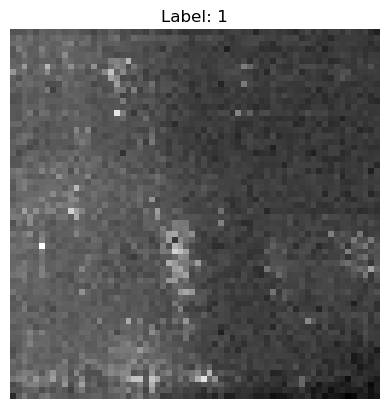

In [32]:
img, label = dataset[0]

print(f"Image shape: {img.shape}") 
print(f"Label: {label}")

if img.shape[0] == 1:
    img_to_show = img.squeeze(0).numpy()
else:
    img_to_show = img.permute(1, 2, 0).numpy()

plt.imshow(img_to_show, cmap='gray')
plt.title(f"Label: {label}")
plt.axis('off')
plt.show()

In [5]:
import torch.nn as nn

class MS_CNN(nn.Module):
    def __init__(self):
        super(MS_CNN, self).__init__()
        self.conv_block1 = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Dropout(0.25)
        )
        self.conv_block2 = nn.Sequential(
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Dropout(0.25)
        )
        self.conv_block3 = nn.Sequential(
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Dropout(0.25)
        )
        self.adaptive_pool = nn.AdaptiveAvgPool2d((4, 4))
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128 * 4 * 4, 128),
            nn.ReLU(),
            nn.Dropout(0.5),
            nn.Linear(128, 1),
            nn.Sigmoid()
        )

    def forward(self, x):
        x = self.conv_block1(x)
        x = self.conv_block2(x)
        x = self.conv_block3(x)
        x = self.adaptive_pool(x)
        x = self.classifier(x)
        return x

In [ ]:
unique_suffix = str(uuid.uuid4())[:8]
EXPERIMENT_NAME = f"CKD_{unique_suffix}"

print(f"\nAttempting to create or set experiment: {EXPERIMENT_NAME}")

try:
    experiment = mlflow.get_experiment_by_name(EXPERIMENT_NAME)
    if experiment is None:
        print(f"Experiment '{EXPERIMENT_NAME}' not found. Creating it WITH EXPLICIT ARTIFACT LOCATION...")

        explicit_artifact_location_relative_to_server_root = EXPERIMENT_NAME
        experiment_id_str = mlflow.create_experiment(
            name=EXPERIMENT_NAME,
            artifact_location=f"mlflow-artifacts:/{explicit_artifact_location_relative_to_server_root}"
        )
        print(f"Successfully created new experiment '{EXPERIMENT_NAME}' with ID: {experiment_id_str} and forced artifact_location.")
        experiment = mlflow.get_experiment(experiment_id_str)
    else:
        experiment_id_str = experiment.experiment_id
        print(f"Using existing experiment '{EXPERIMENT_NAME}' with ID: {experiment_id_str}")

    print(f"  Experiment Name: {experiment.name}")
    print(f"  Experiment ID: {experiment.experiment_id}")
    print(f"  CRITICAL CHECK - Experiment Artifact Location: {experiment.artifact_location}")

    mlflow.set_experiment(experiment_name=EXPERIMENT_NAME)
    print(f"Successfully set active experiment to '{EXPERIMENT_NAME}'")

except Exception as e:
    print(f"Error during experiment creation or setting for '{EXPERIMENT_NAME}': {e}")
    import traceback
    traceback.print_exc()
    raise

client_identifier = "aachen"
timestamp = int(time.time())
run_name = f"{client_identifier}_Run_{timestamp}"

print(f"\nStarting MLflow run: {run_name} for client: {client_identifier}")

try:
    with mlflow.start_run(run_name=run_name) as run:
        print(f"  Successfully started MLflow Run.")
        print(f"    Run ID: {run.info.run_id}")
        print(f"    Experiment ID (from run info): {run.info.experiment_id}")
        print(f"    CRITICAL CHECK - Artifact URI (for this run, from run info): {run.info.artifact_uri}")

        mlflow.log_param("client_type", client_identifier)

        dummy_artifact_filename = f"test_artifact_{client_identifier.lower()}.txt"
        local_artifact_file_path = os.path.join(os.getcwd(), dummy_artifact_filename)
        with open(local_artifact_file_path, "w") as f:
            f.write("Test content for artifact location.")
        print(f"  Created local artifact file: {local_artifact_file_path}")

        print(f"  Attempting to log artifact '{local_artifact_file_path}'")
        mlflow.log_artifact(local_artifact_file_path, artifact_path="client_specific_artifacts")
        print(f"  Artifact '{dummy_artifact_filename}' logged successfully to server.")
        os.remove(local_artifact_file_path)

        print(f"\n--- Test artifact logging from {client_identifier} Successful ---\n")

        num_epochs = 1
        learning_rate = 1e-3
        batch_size = 32
        image_size = "64x64"
        model_type = "MS_CNN"

        mlflow.log_param("model_type", model_type)
        mlflow.log_param("image_size", image_size)
        mlflow.log_param("epochs", num_epochs)
        mlflow.log_param("batch_size", batch_size)
        mlflow.log_param("learning_rate", learning_rate)

        device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
        model = MS_CNN().to(device)
        criterion = nn.BCELoss()
        optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)

        for epoch in range(num_epochs):
            model.train()
            train_losses = []
            train_preds = []
            train_labels = []

            for imgs, labels in train_loader:
                imgs = imgs.to(device)
                labels = labels.to(device).unsqueeze(1).float()

                optimizer.zero_grad()
                outputs = model(imgs)
                loss = criterion(outputs, labels)
                loss.backward()
                optimizer.step()

                train_losses.append(loss.item())
                preds = (outputs.detach().cpu().numpy() > 0.5).astype(int).flatten()
                train_preds.extend(preds)
                train_labels.extend(labels.detach().cpu().numpy().astype(int).flatten())

            train_loss = np.mean(train_losses)
            train_acc = accuracy_score(train_labels, train_preds)
            train_precision = precision_score(train_labels, train_preds, zero_division=0)
            train_recall = recall_score(train_labels, train_preds, zero_division=0)

            if len(set(train_labels)) == 2:
                train_auc = roc_auc_score(train_labels, train_preds)
            else:
                train_auc = None
                
            model.eval()
            val_losses = []
            val_preds = []
            val_labels = []

            with torch.no_grad():
                for imgs, labels in val_loader:
                    imgs = imgs.to(device)
                    labels = labels.to(device).unsqueeze(1).float()

                    outputs = model(imgs)
                    loss = criterion(outputs, labels)
                    val_losses.append(loss.item())

                    preds = (outputs.cpu().numpy() > 0.5).astype(int).flatten()
                    val_preds.extend(preds)
                    val_labels.extend(labels.cpu().numpy().astype(int).flatten())

            val_loss = np.mean(val_losses)
            val_acc = accuracy_score(val_labels, val_preds)
            val_precision = precision_score(val_labels, val_preds, zero_division=0)
            val_recall = recall_score(val_labels, val_preds, zero_division=0)

            if len(set(val_labels)) == 2:
                val_auc = roc_auc_score(val_labels, val_preds)
            else:
                val_auc = None
            
            mlflow.log_metric("train_loss", train_loss, step=epoch)
            mlflow.log_metric("train_acc", train_acc, step=epoch)
            mlflow.log_metric("train_precision", train_precision, step=epoch)
            mlflow.log_metric("train_recall", train_recall, step=epoch)
            if train_auc is not None:
                mlflow.log_metric("train_auc", train_auc, step=epoch)

            mlflow.log_metric("val_loss", val_loss, step=epoch)
            mlflow.log_metric("val_acc", val_acc, step=epoch)
            mlflow.log_metric("val_precision", val_precision, step=epoch)
            mlflow.log_metric("val_recall", val_recall, step=epoch)
            if val_auc is not None:
                mlflow.log_metric("val_auc", val_auc, step=epoch)

            signature = infer_signature(input_example.cpu(), example_output)

            print(
                f"Epoch {epoch+1}/{num_epochs} | "
                f"Train Loss: {train_loss:.4f}, Train Acc: {train_acc:.4f}, Train AUC: {train_auc if train_auc is not None else 'N/A'} | "
                f"Val Loss: {val_loss:.4f}, Val Acc: {val_acc:.4f}, Val AUC: {val_auc if val_auc is not None else 'N/A'}"
            )

            mlflow.pytorch.log_model(
                model,
                artifact_path="ckd_msnetcnn_model",
                signature=signature,
                input_example=input_example.cpu(),
                pip_requirements="pip_requirements.txt" 
            )
            
        print("\nTraining complete, model logged to MLflow.")

except Exception as e:
    print(f"\nMLflow run for {client_identifier} FAILED")
    print(f"Error: {e}")
    import traceback
    traceback.print_exc()
    raise

In [19]:
plt.ioff()

DATA_ROOT = "../ahen_data/filtered_tsv_2"
IMAGE_ROOT = "images"

IMAGE_TYPES = {
    "grayscale_heatmap": os.path.join(IMAGE_ROOT, "grayscale_heatmap"),
    "pseudocolor_heatmap": os.path.join(IMAGE_ROOT, "pseudocolor_heatmap"),
    "rgb_mz_split": os.path.join(IMAGE_ROOT, "rgb_mz_split"),
    "lineplot_intensity": os.path.join(IMAGE_ROOT, "lineplot_intensity"),
    "scatterplot": os.path.join(IMAGE_ROOT, "scatterplot"),
    "tic_plot": os.path.join(IMAGE_ROOT, "tic_plot"),
    "recurrence_plot": os.path.join(IMAGE_ROOT, "recurrence_plot"),
}

for subfolder in IMAGE_TYPES.values():
    os.makedirs(subfolder, exist_ok=True)

In [51]:
def load_and_downsample(filepath, sample_size=200_000):
    """
    1) Read all columns as strings to avoid mixed‐type errors.
    2) Convert to float (invalid → NaN), drop NaNs.
    3) If row‐count > sample_size, randomly sample down to sample_size.
    Returns a clean DataFrame with numeric columns ['time','mz','intensity'].
    """
    df = pd.read_csv(filepath, sep='\t', names=["time", "mz", "intensity"], 
                     dtype=str, low_memory=False)
    for col in ["time", "mz", "intensity"]:
        df[col] = pd.to_numeric(df[col], errors="coerce")
    df = df.dropna(subset=["time", "mz", "intensity"])
    if len(df) > sample_size:
        df = df.sample(n=sample_size, random_state=42)
    return df


In [65]:
def generate_grayscale_heatmap(filepath, bins=(128, 128)):
    filename = os.path.splitext(os.path.basename(filepath))[0]
    pid = filename.replace("WCmsdata_s", "")
    base = f"{pid}.png"
    save_path = os.path.join(IMAGE_TYPES["grayscale_heatmap"], base)
    if os.path.exists(save_path):
        return
    df = load_and_downsample(filepath)
    # Bin on (mz, time), weight by intensity
    heatmap, xedges, yedges = np.histogram2d(
        df["mz"], df["time"],
        bins=bins,
        range=[[50, 1650], [0, 37]],
        weights=df["intensity"]
    )
    heatmap = np.log1p(heatmap) # Log‐scale
    heatmap -= heatmap.min() # Normalize to [0,1]
    heatmap /= heatmap.max() if heatmap.max() > 0 else 1
    img = Image.fromarray((heatmap * 255).astype(np.uint8), mode="L")
    img.save(save_path)

In [67]:
def generate_pseudocolor_heatmap(filepath, bins=(128, 128)):
    filename = os.path.splitext(os.path.basename(filepath))[0]
    pid = filename.replace("WCmsdata_s", "")
    base = f"{pid}.png"    
    save_path = os.path.join(IMAGE_TYPES["pseudocolor_heatmap"], base)
    if os.path.exists(save_path):
        return
    df = load_and_downsample(filepath)
    heatmap, xedges, yedges = np.histogram2d(
        df["mz"], df["time"],
        bins=bins,
        range=[[50, 1650], [0, 37]],
        weights=df["intensity"]
    )
    heatmap = np.log1p(heatmap)
    heatmap -= heatmap.min()
    heatmap /= heatmap.max() if heatmap.max() > 0 else 1
    cmap = plt.get_cmap("jet")
    colored = cmap(heatmap) # RGBA floats in [0,1]
    rgb = (colored[:, :, :3] * 255).astype(np.uint8)
    img = Image.fromarray(rgb, mode="RGB")
    img.save(save_path)

In [68]:
def generate_rgb_mz_split(filepath, bins=(128, 128)):
    filename = os.path.splitext(os.path.basename(filepath))[0]
    pid = filename.replace("WCmsdata_s", "")
    base = f"{pid}.png"    
    save_path = os.path.join(IMAGE_TYPES["rgb_mz_split"], base)
    if os.path.exists(save_path):
        return
    df = load_and_downsample(filepath)
    # Define three m/z ranges
    mz_bands = [(50, 550), (550, 1100), (1100, 1650)]
    channels = []
    for mz_range in mz_bands:
        mask = (df["mz"] >= mz_range[0]) & (df["mz"] < mz_range[1])
        sub = df[mask]
        heatmap, _, _ = np.histogram2d(
            sub["mz"], sub["time"],
            bins=bins,
            range=[mz_range, [0, 37]],
            weights=sub["intensity"]
        )
        heatmap = np.log1p(heatmap)
        heatmap -= heatmap.min()
        heatmap /= heatmap.max() if heatmap.max() > 0 else 1
        channels.append((heatmap * 255).astype(np.uint8))
    rgb = np.stack(channels, axis=-1)
    img = Image.fromarray(rgb, mode="RGB")
    img.save(save_path)

In [69]:
def generate_lineplot_intensity(filepath, img_size=(128, 128)):
    filename = os.path.splitext(os.path.basename(filepath))[0]
    pid = filename.replace("WCmsdata_s", "")
    base = f"{pid}.png"    
    save_path = os.path.join(IMAGE_TYPES["lineplot_intensity"], base)
    if os.path.exists(save_path):
        return
    df = load_and_downsample(filepath, sample_size=500_000)
    df_sorted = df.sort_values("time")
    times = df_sorted["time"].values
    intensities = df_sorted["intensity"].values
    fig, ax = plt.subplots(figsize=(img_size[0] / 32, img_size[1] / 32), dpi=32)
    ax.plot(times, intensities, linewidth=0.5, color="black")
    ax.axis("off")
    buf = io.BytesIO()
    plt.savefig(buf, format="png", bbox_inches="tight", pad_inches=0)
    plt.close(fig)
    img = Image.open(buf).convert("L").resize(img_size)
    img.save(save_path)

In [70]:
def generate_scatterplot(filepath, img_size=(128, 128)):
    filename = os.path.splitext(os.path.basename(filepath))[0]
    pid = filename.replace("WCmsdata_s", "")
    base = f"{pid}.png"    
    save_path = os.path.join(IMAGE_TYPES["scatterplot"], base)
    if os.path.exists(save_path):
        return
    df = load_and_downsample(filepath, sample_size=200_000)
    fig, ax = plt.subplots(figsize=(img_size[0] / 32, img_size[1] / 32), dpi=32)
    sc = ax.scatter(
        df["time"], df["mz"],
        c=df["intensity"], s=1, cmap="gray", marker="."
    )
    ax.set_xlim(0, 37)
    ax.set_ylim(50, 1650)
    ax.axis("off")
    buf = io.BytesIO()
    plt.savefig(buf, format="png", bbox_inches="tight", pad_inches=0)
    plt.close(fig)
    img = Image.open(buf).convert("L").resize(img_size)
    img.save(save_path)

In [71]:
def generate_tic_plot(filepath, img_size=(128, 128)):
    filename = os.path.splitext(os.path.basename(filepath))[0]
    pid = filename.replace("WCmsdata_s", "")
    base = f"{pid}.png"    
    save_path = os.path.join(IMAGE_TYPES["tic_plot"], base)
    if os.path.exists(save_path):
        return
    df = load_and_downsample(filepath, sample_size=500_000)
    bins = np.linspace(df["time"].min(), df["time"].max(), 200)
    indices = np.digitize(df["time"], bins)
    tic = [df["intensity"][indices == i].sum() for i in range(1, len(bins))]
    times = (bins[:-1] + bins[1:]) / 2
    fig, ax = plt.subplots(figsize=(img_size[0] / 32, img_size[1] / 32), dpi=32)
    ax.plot(times, tic, linewidth=0.5, color="blue")
    ax.axis("off")
    buf = io.BytesIO()
    plt.savefig(buf, format="png", bbox_inches="tight", pad_inches=0)
    plt.close(fig)
    img = Image.open(buf).convert("L").resize(img_size)
    img.save(save_path)

In [72]:
def generate_recurrence_plot(filepath, img_size=(128, 128)):
    filename = os.path.splitext(os.path.basename(filepath))[0]
    pid = filename.replace("WCmsdata_s", "")
    base = f"{pid}.png"    
    save_path = os.path.join(IMAGE_TYPES["recurrence_plot"], base)
    if os.path.exists(save_path):
        return
    df = load_and_downsample(filepath, sample_size=500_000)
    df_sorted = df.sort_values("time")
    intensities = df_sorted["intensity"].values
    length = img_size[0]
    if len(intensities) > length:
        intensities = np.interp(
            np.linspace(0, len(intensities) - 1, length),
            np.arange(len(intensities)),
            intensities
        )
    ts = (intensities - intensities.min()) / (intensities.max() - intensities.min() + 1e-9)
    diff_mat = np.abs(ts[:, None] - ts[None, :])
    eps = 0.1 * diff_mat.max()
    rec = (diff_mat < eps).astype(np.uint8) * 255
    img = Image.fromarray(rec).resize(img_size)
    img.save(save_path)

In [ ]:
try:
    file_list = [f for f in os.listdir(DATA_ROOT) if f.endswith(".tsv")]
except FileNotFoundError:
    raise FileNotFoundError(f"The folder '{DATA_ROOT}' does not exist. Please set DATA_ROOT to the correct path.")

for fname in file_list:
    fullpath = os.path.join(DATA_ROOT, fname)
    generate_grayscale_heatmap(fullpath)
    generate_pseudocolor_heatmap(fullpath)
    generate_rgb_mz_split(fullpath)
    generate_lineplot_intensity(fullpath)
    generate_scatterplot(fullpath)
    generate_tic_plot(fullpath)
    generate_recurrence_plot(fullpath)

print("Images generated. Check 'images/' subfolders.")

In [6]:
try:
    file_list = [f for f in os.listdir(DATA_ROOT) if f.endswith(".tsv")]
except FileNotFoundError:
    raise FileNotFoundError(f"The folder '{DATA_ROOT}' does not exist. Please set DATA_ROOT to the correct path.")

for fname in file_list:
    fullpath = os.path.join(DATA_ROOT, fname)
    stem = os.path.splitext(os.path.basename(fullpath))[0]   
    pid = stem.replace("WCmsdata_s", "")                     

    missing_types = []
    for img_type, folder in IMAGE_TYPES.items():
        target_path = os.path.join(folder, f"{pid}.png")
        if not os.path.exists(target_path):
            missing_types.append(img_type)

    if not missing_types:
        continue

    if "grayscale_heatmap" in missing_types:
        print(fname)
        generate_grayscale_heatmap(fullpath)
    if "pseudocolor_heatmap" in missing_types:
        generate_pseudocolor_heatmap(fullpath)
    if "rgb_mz_split" in missing_types:
        generate_rgb_mz_split(fullpath)
    if "lineplot_intensity" in missing_types:
        generate_lineplot_intensity(fullpath)
    if "scatterplot" in missing_types:
        generate_scatterplot(fullpath)
    if "tic_plot" in missing_types:
        generate_tic_plot(fullpath)
    if "recurrence_plot" in missing_types:
        generate_recurrence_plot(fullpath)

print("Done. Only missing images were generated.")


NameError: name 'DATA_ROOT' is not defined

In [8]:
# CNN Model Definitions
class SimpleCNN(nn.Module):
    def __init__(self, num_classes=1):
        super(SimpleCNN, self).__init__()
        self.conv1 = nn.Conv2d(3, 16, kernel_size=3, padding=1)
        self.relu1 = nn.ReLU()
        self.pool1 = nn.MaxPool2d(kernel_size=2, stride=2)
        self.conv2 = nn.Conv2d(16, 32, kernel_size=3, padding=1)
        self.relu2 = nn.ReLU()
        self.pool2 = nn.MaxPool2d(kernel_size=2, stride=2)
        with torch.no_grad():
            dummy_input = torch.zeros(1, 3, IMAGE_SIZE[0], IMAGE_SIZE[1])
            dummy_out = self.pool2(self.relu2(self.conv2(self.pool1(self.relu1(self.conv1(dummy_input))))))
            flattened_size = dummy_out.numel()
        self.fc1 = nn.Linear(flattened_size, 128)
        self.relu3 = nn.ReLU()
        self.fc2 = nn.Linear(128, num_classes)
        self.sigmoid = nn.Sigmoid()
    def forward(self, x):
        x = self.pool1(self.relu1(self.conv1(x))); x = self.pool2(self.relu2(self.conv2(x)))
        x = x.view(x.size(0), -1); x = self.relu3(self.fc1(x)); x = self.fc2(x); x = self.sigmoid(x)
        return x

class DeeperCNN(nn.Module):
    def __init__(self, num_classes=1):
        super(DeeperCNN, self).__init__()
        self.conv_block1 = nn.Sequential(nn.Conv2d(3, 32, kernel_size=3, padding=1), nn.BatchNorm2d(32), nn.ReLU(), nn.MaxPool2d(kernel_size=2, stride=2))
        self.conv_block2 = nn.Sequential(nn.Conv2d(32, 64, kernel_size=3, padding=1), nn.BatchNorm2d(64), nn.ReLU(), nn.MaxPool2d(kernel_size=2, stride=2))
        self.conv_block3 = nn.Sequential(nn.Conv2d(64, 128, kernel_size=3, padding=1), nn.BatchNorm2d(128), nn.ReLU(), nn.MaxPool2d(kernel_size=2, stride=2))
        with torch.no_grad():
            dummy_input = torch.zeros(1, 3, IMAGE_SIZE[0], IMAGE_SIZE[1])
            dummy_out = self.conv_block3(self.conv_block2(self.conv_block1(dummy_input)))
            flattened_size = dummy_out.numel()
        self.fc_block = nn.Sequential(nn.Linear(flattened_size, 256), nn.ReLU(), nn.Dropout(0.5), nn.Linear(256, num_classes), nn.Sigmoid())
    def forward(self, x):
        x = self.conv_block1(x); x = self.conv_block2(x); x = self.conv_block3(x)
        x = x.view(x.size(0), -1); x = self.fc_block(x)
        return x

def get_resnet18_model(pretrained=True, num_classes=1):
    weights = ResNet18_Weights.IMAGENET1K_V1 if pretrained else None
    model = resnet18(weights=weights)
    model.fc = nn.Sequential(nn.Linear(model.fc.in_features, num_classes), nn.Sigmoid())
    return model

def get_vgg16_bn_model(pretrained=True, num_classes=1):
    weights = VGG16_BN_Weights.IMAGENET1K_V1 if pretrained else None
    model = vgg16_bn(weights=weights)
    model.classifier[6] = nn.Linear(model.classifier[6].in_features, num_classes)
    return nn.Sequential(model, nn.Sigmoid())

def get_efficientnet_b0_model(pretrained=True, num_classes=1):
    try:
        weights = EfficientNet_B0_Weights.IMAGENET1K_V1 if pretrained else None
        model = efficientnet_b0(weights=weights)
        model.classifier[1] = nn.Linear(model.classifier[1].in_features, num_classes)
        return nn.Sequential(model, nn.Sigmoid())
    except Exception as e:
        print(f"Warning: Could not load EfficientNet_B0 (torchvision version or weights issue): {e}. Skipping this model.")
        return None

In [9]:
MODEL_ARCHITECTURES = {
    "SimpleCNN": lambda use_pt: SimpleCNN(num_classes=1),
    "DeeperCNN": lambda use_pt: DeeperCNN(num_classes=1),
    "ResNet18": get_resnet18_model,
    "VGG16_BN": get_vgg16_bn_model,
    "EfficientNetB0": get_efficientnet_b0_model,
}

In [10]:
class ImageDatasetFromLists(Dataset):
    def __init__(self, image_folder, label_dict, transform=None):
        self.image_folder = image_folder
        self.transform = transform
        self.filepaths = []
        self.labels = []
        for pid, label in label_dict.items():
            img_path = os.path.join(image_folder, f"{pid}.png")
            if os.path.exists(img_path):
                self.filepaths.append(img_path)
                self.labels.append(label)
        if not self.filepaths:
            raise ValueError(f"No PNGs found in {image_folder} matching label_dict keys.")

    def __len__(self):
        return len(self.filepaths)

    def __getitem__(self, idx):
        img = Image.open(self.filepaths[idx])
        if self.transform:
            img = self.transform(img)
        label = torch.tensor(self.labels[idx], dtype=torch.float32)
        return img, label

In [11]:
# 1) SimpleCNN
class SimpleCNN(nn.Module):
    def __init__(self, in_channels, num_classes=1):
        super(SimpleCNN, self).__init__()
        self.conv_block1 = nn.Sequential(
            nn.Conv2d(in_channels, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Dropout(0.25)
        )
        self.conv_block2 = nn.Sequential(
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Dropout(0.25)
        )
        self.adaptive_pool = nn.AdaptiveAvgPool2d((8, 8))
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 8 * 8, 128),
            nn.ReLU(),
            nn.Dropout(0.5),
            nn.Linear(128, num_classes),
            nn.Sigmoid()
        )

    def forward(self, x):
        x = self.conv_block1(x)
        x = self.conv_block2(x)
        x = self.adaptive_pool(x)
        x = self.classifier(x)
        return x

# 2) DeeperCNN
class DeeperCNN(nn.Module):
    def __init__(self, in_channels, num_classes=1):
        super(DeeperCNN, self).__init__()
        self.conv_block1 = nn.Sequential(
            nn.Conv2d(in_channels, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.Conv2d(32, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Dropout(0.25)
        )
        self.conv_block2 = nn.Sequential(
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.Conv2d(64, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Dropout(0.25)
        )
        self.conv_block3 = nn.Sequential(
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.Conv2d(128, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Dropout(0.25)
        )
        self.adaptive_pool = nn.AdaptiveAvgPool2d((4, 4))
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128 * 4 * 4, 256),
            nn.ReLU(),
            nn.Dropout(0.5),
            nn.Linear(256, num_classes),
            nn.Sigmoid()
        )

    def forward(self, x):
        x = self.conv_block1(x)
        x = self.conv_block2(x)
        x = self.conv_block3(x)
        x = self.adaptive_pool(x)
        x = self.classifier(x)
        return x

# 3) get_resnet18_custom_model
def get_resnet18_custom_model(in_channels, num_classes):
    model = resnet18(weights=None)  # no pretrained weights
    if in_channels != 3:
        model.conv1 = nn.Conv2d(in_channels, 64, kernel_size=7, stride=2, padding=3, bias=False)
    model.fc = nn.Linear(model.fc.in_features, num_classes)
    return nn.Sequential(model, nn.Sigmoid())

# 4) get_vgg16_bn_model
def get_vgg16_bn_model(in_channels, num_classes, pretrained=True):
    try:
        weights = VGG16_BN_Weights.IMAGENET1K_V1 if pretrained else None
        model = vgg16_bn(weights=weights)
        if in_channels == 1:
            model.features[0] = nn.Conv2d(1, 64, kernel_size=3, padding=1)
        model.classifier[6] = nn.Linear(4096, num_classes)
        return nn.Sequential(model, nn.Sigmoid())
    except Exception as e:
        print(f"Warning: Could not load VGG16_BN: {e}")
        return None

#get_efficientnet_b0_model
def get_efficientnet_b0_model(in_channels, num_classes, pretrained=True):
    try:
        weights = EfficientNet_B0_Weights.IMAGENET1K_V1 if pretrained else None
        model = efficientnet_b0(weights=weights)
        if in_channels == 1:
            model.features[0][0] = nn.Conv2d(1, 32, kernel_size=3, stride=2, padding=1, bias=False)
        model.classifier[1] = nn.Linear(model.classifier[1].in_features, num_classes)
        return nn.Sequential(model, nn.Sigmoid())
    except Exception as e:
        print(f"Warning: Could not load EfficientNet_B0: {e}")
        return None

#get_resnet18_pretrained_model
def get_resnet18_pretrained_model(in_channels, num_classes):
    weights = ResNet18_Weights.IMAGENET1K_V1
    model = resnet18(weights=weights)
    if in_channels != 3:
        model.conv1 = nn.Conv2d(in_channels, 64, kernel_size=7, stride=2, padding=3, bias=False)
    model.fc = nn.Linear(model.fc.in_features, num_classes)
    return nn.Sequential(model, nn.Sigmoid())


In [13]:
class ImageDatasetFromLists(Dataset):
    def __init__(self, folder, labels, transform=None):
        self.files, self.labels = [], []
        for pid, lab in labels.items():
            path = os.path.join(folder, pid + ".png")
            if os.path.exists(path):
                self.files.append(path)
                self.labels.append(lab)
        if not self.files:
            raise RuntimeError(f"No images in {folder}")
        self.transform = transform
    def __len__(self):
        return len(self.files)
    def __getitem__(self, i):
        img = Image.open(self.files[i])
        if self.transform:
            img = self.transform(img)
        return img, torch.tensor(self.labels[i], dtype=torch.float32)

In [16]:
def plot_and_log_roc_curve(y_true, y_probs, prefix):
    fpr, tpr, _ = roc_curve(y_true, y_probs)
    plt.figure()
    plt.plot(fpr, tpr, label=f'ROC curve (AUC = {roc_auc_score(y_true, y_probs):.2f})')
    plt.plot([0, 1], [0, 1], 'k--')
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.title("ROC Curve")
    plt.legend(loc="lower right")
    roc_path = f"{prefix}_roc.png"
    plt.savefig(roc_path)
    mlflow.log_artifact(roc_path)
    plt.close()

In [ ]:
def plot_and_log_confusion_matrix(y_true, y_pred, prefix):
    cm = confusion_matrix(y_true, y_pred)
    plt.figure()
    plt.imshow(cm, interpolation='nearest', cmap=plt.cm.Blues)
    plt.title("Confusion Matrix")
    plt.colorbar()
    classes = ['Non-CKD', 'CKD']
    tick_marks = np.arange(len(classes))
    plt.xticks(tick_marks, classes, rotation=45)
    plt.yticks(tick_marks, classes)

    thresh = cm.max() / 2.
    for i, j in np.ndindex(cm.shape):
        plt.text(j, i, f"{cm[i, j]}", horizontalalignment="center",
                 color="white" if cm[i, j] > thresh else "black")

    plt.ylabel('True label')
    plt.xlabel('Predicted label')
    cm_path = f"{prefix}_confusion_matrix.png"
    plt.savefig(cm_path)
    mlflow.log_artifact(cm_path)
    plt.close()

In [17]:
def plot_and_log_roc(y_true, probs):
    fpr, tpr, _ = roc_curve(y_true, probs)
    plt.figure()
    plt.plot(fpr, tpr, label=f"AUC = {roc_auc_score(y_true, probs):.2f}")
    plt.plot([0, 1], [0, 1], "k--")
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.title("ROC Curve")
    plt.legend()
    fig_path = "val_roc_curve.png"
    plt.savefig(fig_path)
    mlflow.log_artifact(fig_path)
    plt.close()

In [18]:
def plot_and_log_cm(y_true, y_pred):
    cm = confusion_matrix(y_true, y_pred)
    fig, ax = plt.subplots()
    im = ax.imshow(cm, cmap='Blues')
    plt.colorbar(im)
    ax.set_title("Confusion Matrix")
    ax.set_xlabel("Predicted")
    ax.set_ylabel("True")
    for i in range(2):
        for j in range(2):
            ax.text(j, i, str(cm[i, j]), ha='center', va='center')
    fig_path = "val_confusion_matrix.png"
    plt.savefig(fig_path)
    mlflow.log_artifact(fig_path)
    plt.close()

In [14]:
def train_and_log(image_type, model_type, lr, batch_size):
    """
    1) Creates MLflow experiment named "CKD_{image_type}_{model_type}_lr{lr}_bs{bs}_{UUID}".
    2) Loads images from images/{image_type}/, labels by label_dict.
    3) Splits by patient-ID 80/20, trains for num_epochs.
    4) Logs metrics and final model to MLflow.
    """
    num_channels = 3 if image_type in ["rgb_mz_split", "pseudocolor_heatmap"] else 1

    transform = transforms.Compose([
        transforms.Resize((64, 64)),
        transforms.ToTensor()
    ])

    folder = IMAGE_TYPES[image_type]
    dataset = ImageDatasetFromLists(folder, label_dict, transform=transform)

    all_pids = [os.path.splitext(os.path.basename(fp))[0] for fp in dataset.files]
    pid_to_indices = {}
    for idx, pid in enumerate(all_pids):
        pid_to_indices.setdefault(pid, []).append(idx)

    unique_pids = list(pid_to_indices.keys())
    random.shuffle(unique_pids)
    split_idx = int(0.8 * len(unique_pids))
    train_pids = set(unique_pids[:split_idx])
    val_pids = set(unique_pids[split_idx:])

    train_indices, val_indices = [], []
    for pid, indices in pid_to_indices.items():
        if pid in train_pids:
            train_indices.extend(indices)
        else:
            val_indices.extend(indices)

    train_ds = Subset(dataset, train_indices)
    val_ds = Subset(dataset, val_indices)
    train_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True, num_workers=2)
    val_loader = DataLoader(val_ds, batch_size=batch_size, shuffle=False, num_workers=2)

    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    model = MODEL_MAPPING[model_type](num_channels).to(device)
    criterion = nn.BCELoss()
    optimizer = optim.Adam(model.parameters(), lr=lr)

    example_img, _ = next(iter(train_loader))
    input_example = example_img[:1].to(device)
    model.eval()
    with torch.no_grad():
        example_output = model(input_example).cpu()
        
    signature = infer_signature(
        input_example.cpu().numpy(), 
        example_output.cpu().numpy()
    )

    unique_suffix = str(uuid.uuid4())[:8]
    EXPERIMENT_NAME = f"CKD_{image_type}_{model_type}_lr{lr}_bs{batch_size}_{unique_suffix}"
    existing = mlflow.get_experiment_by_name(EXPERIMENT_NAME)
    if existing is None:
        artifact_loc = os.path.join(os.getcwd(), "mlflow-artifacts", EXPERIMENT_NAME)
        os.makedirs(artifact_loc, exist_ok=True)
        experiment_id = mlflow.create_experiment(
            name=EXPERIMENT_NAME,
            artifact_location=artifact_loc
        )
        experiment = mlflow.get_experiment(experiment_id)
    else:
        experiment = existing

    print(f"Using experiment '{experiment.name}' (ID={experiment.experiment_id})")
    mlflow.set_experiment(experiment_name=EXPERIMENT_NAME)

    run_name = f"{image_type}_{model_type}_lr{lr}_bs{batch_size}"
    with mlflow.start_run(run_name=run_name):
        mlflow.log_param("image_type", image_type)
        mlflow.log_param("model_type", model_type)
        mlflow.log_param("learning_rate", lr)
        mlflow.log_param("batch_size", batch_size)
        mlflow.log_param("num_epochs", num_epochs)

        for epoch in range(num_epochs):
            model.train()
            train_losses, train_preds, train_labels = [], [], []
            for imgs, labels in train_loader:
                imgs = imgs.to(device)
                labels = labels.to(device).unsqueeze(1).float()

                optimizer.zero_grad()
                outputs = model(imgs)
                loss = criterion(outputs, labels)
                loss.backward()
                optimizer.step()

                train_losses.append(loss.item())
                preds = (outputs.detach().cpu().numpy() > 0.5).astype(int).flatten()
                train_preds.extend(preds)
                train_labels.extend(labels.detach().cpu().numpy().astype(int).flatten())

            train_loss = np.mean(train_losses)
            train_acc = accuracy_score(train_labels, train_preds)
            train_precision = precision_score(train_labels, train_preds, zero_division=0)
            train_recall = recall_score(train_labels, train_preds, zero_division=0)
            train_auc = roc_auc_score(train_labels, train_preds) if len(set(train_labels)) == 2 else None

            model.eval()
            val_losses, val_preds, val_labels = [], [], []
            with torch.no_grad():
                for imgs, labels in val_loader:
                    imgs = imgs.to(device)
                    labels = labels.to(device).unsqueeze(1).float()
                    outputs = model(imgs)
                    loss = criterion(outputs, labels)
                    val_losses.append(loss.item())

                    preds = (outputs.cpu().numpy() > 0.5).astype(int).flatten()
                    val_preds.extend(preds)
                    val_labels.extend(labels.cpu().numpy().astype(int).flatten())

            val_loss = np.mean(val_losses)
            val_acc = accuracy_score(val_labels, val_preds)
            val_precision = precision_score(val_labels, val_preds, zero_division=0)
            val_recall = recall_score(val_labels, val_preds, zero_division=0)
            val_auc = roc_auc_score(val_labels, val_preds) if len(set(val_labels)) == 2 else None

            mlflow.log_metric("train_loss", train_loss, step=epoch)
            mlflow.log_metric("train_acc", train_acc, step=epoch)
            mlflow.log_metric("train_precision", train_precision, step=epoch)
            mlflow.log_metric("train_recall", train_recall, step=epoch)
            if train_auc is not None:
                mlflow.log_metric("train_auc", train_auc, step=epoch)

            mlflow.log_metric("val_loss", val_loss, step=epoch)
            mlflow.log_metric("val_acc", val_acc, step=epoch)
            mlflow.log_metric("val_precision", val_precision, step=epoch)
            mlflow.log_metric("val_recall", val_recall, step=epoch)
            if val_auc is not None:
                mlflow.log_metric("val_auc", val_auc, step=epoch)

            print(
                f"[{image_type} | {model_type} | lr={lr} | bs={batch_size}] "
                f"Epoch {epoch+1}/{num_epochs}: "
                f"Train Acc={train_acc:.4f}, Val Acc={val_acc:.4f}"
            )

        mlflow.pytorch.log_model(
            model,
            artifact_path="model",
            signature=signature,
            input_example=input_example.cpu().numpy()
        )

    print(f"Finished experiment: {EXPERIMENT_NAME}")

In [15]:
def train_and_log_new(image_type, model_type, lr, batch_size):
    num_channels = 3 if image_type in ["rgb_mz_split", "pseudocolor_heatmap"] else 1

    transform = transforms.Compose([
        transforms.Resize((64, 64)),
        transforms.ToTensor()
    ])

    folder = IMAGE_TYPES[image_type]
    dataset = ImageDatasetFromLists(folder, label_dict, transform=transform)

    all_pids = [os.path.splitext(os.path.basename(fp))[0] for fp in dataset.files]
    pid_to_indices = {}
    for idx, pid in enumerate(all_pids):
        pid_to_indices.setdefault(pid, []).append(idx)

    unique_pids = list(pid_to_indices.keys())
    random.shuffle(unique_pids)
    split_idx = int(0.8 * len(unique_pids))
    train_pids = set(unique_pids[:split_idx])
    val_pids = set(unique_pids[split_idx:])

    train_indices, val_indices = [], []
    for pid, indices in pid_to_indices.items():
        if pid in train_pids:
            train_indices.extend(indices)
        else:
            val_indices.extend(indices)

    train_ds = Subset(dataset, train_indices)
    val_ds = Subset(dataset, val_indices)
    train_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True, num_workers=2)
    val_loader = DataLoader(val_ds, batch_size=batch_size, shuffle=False, num_workers=2)

    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    model = MODEL_MAPPING_NEW[model_type](num_channels).to(device)
    criterion = nn.BCELoss()
    optimizer = optim.Adam(model.parameters(), lr=lr)

    example_img, _ = next(iter(train_loader))
    input_example = example_img[:1].to(device)
    model.eval()
    with torch.no_grad():
        example_output = model(input_example).cpu()
    signature = infer_signature(input_example.cpu().numpy(), example_output.cpu().numpy())

    unique_suffix = str(uuid.uuid4())[:8]
    EXPERIMENT_NAME = f"CKD_{image_type}_{model_type}_lr{lr}_bs{batch_size}_{unique_suffix}"
   # artifact_loc = os.path.join(os.getcwd(), "mlflow-artifacts", EXPERIMENT_NAME)
   # os.makedirs(artifact_loc, exist_ok=True)
    try:
        experiment = mlflow.get_experiment_by_name(EXPERIMENT_NAME)
        if experiment is None:
            print(f"Creating new experiment '{EXPERIMENT_NAME}' with server-side artifact storage.")
            artifact_location = f"mlflow-artifacts:/{EXPERIMENT_NAME}"
            mlflow.create_experiment(name=EXPERIMENT_NAME, artifact_location=artifact_location)
        
        mlflow.set_experiment(experiment_name=EXPERIMENT_NAME)
        print(f"Successfully set experiment. Artifacts will be proxied through the server.")

    except Exception as e:
        print(f"Failed during experiment setup: {e}")
        raise

    with mlflow.start_run(run_name=f"{image_type}_{model_type}_lr{lr}_bs{batch_size}"):
        print(f"Logging to Experiment '{EXPERIMENT_NAME}' on server: {mlflow.get_tracking_uri()}")
        print(f"Run Artifacts will be stored at: {mlflow.active_run().info.artifact_uri}")
        mlflow.log_params({
            "image_type": image_type,
            "model_type": model_type,
            "learning_rate": lr,
            "batch_size": batch_size,
            "num_epochs": num_epochs
        })

        for epoch in range(num_epochs):
            model.train()
            train_losses, train_preds, train_labels = [], [], []
            for imgs, labels in train_loader:
                imgs = imgs.to(device)
                labels = labels.to(device).unsqueeze(1).float()

                optimizer.zero_grad()
                outputs = model(imgs)
                loss = criterion(outputs, labels)
                loss.backward()
                optimizer.step()

                train_losses.append(loss.item())
                preds = (outputs.detach().cpu().numpy() > 0.5).astype(int).flatten()
                train_preds.extend(preds)
                train_labels.extend(labels.cpu().numpy().astype(int).flatten())

            train_loss = np.mean(train_losses)
            train_acc = accuracy_score(train_labels, train_preds)
            train_precision = precision_score(train_labels, train_preds, zero_division=0)
            train_recall = recall_score(train_labels, train_preds, zero_division=0)
            train_f1 = f1_score(train_labels, train_preds, zero_division=0)
            train_auc = roc_auc_score(train_labels, train_preds) if len(set(train_labels)) == 2 else None

            model.eval()
            val_losses, val_preds, val_labels, val_probs = [], [], [], []
            with torch.no_grad():
                for imgs, labels in val_loader:
                    imgs = imgs.to(device)
                    labels = labels.to(device).unsqueeze(1).float()
                    outputs = model(imgs)
                    probs = outputs.cpu().numpy().flatten()
                    loss = criterion(outputs, labels)
                    val_losses.append(loss.item())
                    preds = (probs > 0.5).astype(int)
                    val_preds.extend(preds)
                    val_labels.extend(labels.cpu().numpy().astype(int).flatten())
                    val_probs.extend(probs)

            val_loss = np.mean(val_losses)
            val_acc = accuracy_score(val_labels, val_preds)
            val_precision = precision_score(val_labels, val_preds, zero_division=0)
            val_recall = recall_score(val_labels, val_preds, zero_division=0)
            val_f1 = f1_score(val_labels, val_preds, zero_division=0)
            val_auc = roc_auc_score(val_labels, val_probs) if len(set(val_labels)) == 2 else None

            mlflow.log_metrics({
                "train_loss": train_loss,
                "train_acc": train_acc,
                "train_precision": train_precision,
                "train_recall": train_recall,
                "train_f1": train_f1,
                "val_loss": val_loss,
                "val_acc": val_acc,
                "val_precision": val_precision,
                "val_recall": val_recall,
                "val_f1": val_f1
            }, step=epoch)

            if train_auc is not None:
                mlflow.log_metric("train_auc", train_auc, step=epoch)
            if val_auc is not None:
                mlflow.log_metric("val_auc", val_auc, step=epoch)

            print(
                f"[{image_type} | {model_type} | lr={lr} | bs={batch_size}] "
                f"Epoch {epoch+1}/{num_epochs}: "
                f"Train Acc={train_acc:.4f}, Val Acc={val_acc:.4f}, F1={val_f1:.4f}"
            )

        # plot_and_log_cm(val_labels, val_preds)
        # if len(set(val_labels)) == 2:
        #     plot_and_log_roc(val_labels, val_probs)

    print(f"Finished experiment: {EXPERIMENT_NAME}")

In [12]:
MODEL_MAPPING = {
    "SimpleCNN": lambda in_ch: SimpleCNN(in_ch, num_classes=1),
    "DeeperCNN": lambda in_ch: DeeperCNN(in_ch, num_classes=1),
    "ResNet18": lambda in_ch: get_resnet18_custom_model(in_ch, num_classes=1),
    "ResNet18_PT": lambda in_ch: get_resnet18_pretrained_model(in_ch, num_classes=1),
    "VGG16_BN": lambda in_ch: get_vgg16_bn_model(in_ch, num_classes=1),
    "EfficientNetB0": lambda in_ch: get_efficientnet_b0_model(in_ch, num_classes=1),
}

In [28]:
MODEL_MAPPING_NEW = {
    "ResNet18": lambda in_ch: get_resnet18_custom_model(in_ch, num_classes=1),
    "VGG16_BN": lambda in_ch: get_vgg16_bn_model(in_ch, num_classes=1),
    # "EfficientNetB0": lambda in_ch: get_efficientnet_b0_model(in_ch, num_classes=1),
    # "ResNet18_PT": lambda in_ch: get_resnet18_pretrained_model(in_ch, num_classes=1)
}

In [27]:
LEARNING_RATES = [1e-2, 1e-3, 1e-4]  # [0.01, 0.001, 0.0001]
BATCH_SIZES = [16, 32, 64]
# LEARNING_RATES = [1e-2, 1e-3]  # [0.01, 0.001, 0.0001]
# BATCH_SIZES = [16, 32]
num_epochs = 10

In [25]:
for model_type in MODEL_MAPPING_NEW:
    try:
        train_and_log_new('scatterplot', model_type, 1e-4, 64)
    except Exception as e:
        print(f"Failed: {img_type}, {model_type}, lr={1e-4}, bs={64} - {e}")

print("\nAll experiments completed and logged.")

Creating new experiment 'CKD_scatterplot_EfficientNetB0_lr0.0001_bs64_4b7491d0' with server-side artifact storage.
Successfully set experiment. Artifacts will be proxied through the server.



KeyboardInterrupt



In [ ]:
for img_type in IMAGE_TYPES.keys():
    for model_type in MODEL_MAPPING_NEW:
        for lr in LEARNING_RATES:
            for bs in BATCH_SIZES:
                try:
                    train_and_log_new(img_type, model_type, lr, bs)
                except Exception as e:
                    print(f"Failed: {img_type}, {model_type}, lr={lr}, bs={bs} - {e}")

print("\nAll experiments completed and logged.")

Creating new experiment 'CKD_grayscale_heatmap_ResNet18_lr0.01_bs16_9fa36d5e' with server-side artifact storage.
Successfully set experiment. Artifacts will be proxied through the server.
Logging to Experiment 'CKD_grayscale_heatmap_ResNet18_lr0.01_bs16_9fa36d5e' on server: https://228a-185-56-250-35.ngrok-free.app
Run Artifacts will be stored at: mlflow-artifacts:/CKD_grayscale_heatmap_ResNet18_lr0.01_bs16_9fa36d5e/71fb51c89a644079aa496f1a79ee3654/artifacts
[grayscale_heatmap | ResNet18 | lr=0.01 | bs=16] Epoch 1/10: Train Acc=0.4909, Val Acc=0.5714, F1=0.7273
[grayscale_heatmap | ResNet18 | lr=0.01 | bs=16] Epoch 2/10: Train Acc=0.5636, Val Acc=0.5714, F1=0.7273
[grayscale_heatmap | ResNet18 | lr=0.01 | bs=16] Epoch 3/10: Train Acc=0.6242, Val Acc=0.5714, F1=0.7273
[grayscale_heatmap | ResNet18 | lr=0.01 | bs=16] Epoch 4/10: Train Acc=0.6424, Val Acc=0.5714, F1=0.7273
[grayscale_heatmap | ResNet18 | lr=0.01 | bs=16] Epoch 5/10: Train Acc=0.5333, Val Acc=0.5714, F1=0.7273
[grayscale_h